# 4 - Train and evaluate the YOLO26 detector

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

repo root: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback
python:   3.14.4 -> /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/bin/python3.14


In [2]:
import json
import importlib.metadata
import platform
import random
import shutil
from dataclasses import asdict, replace

import numpy as np
import torch
import torchvision
import ultralytics
from ultralytics import YOLO
from ultralytics.utils import SETTINGS

from IPython.display import Image, display

from perception.detection import DetectorConfig, validate_dataset, evaluate_predictions, ultralytics_metrics
from perception.detection.results import result_predictions
from perception.contracts import DetectionFrame, FrameStamp, SourceMetadata, SourceType
from perception.inference.yolo import detection_from_result
from perception.jsonio import write_json

`configs/detector.json` is the reproducible source of truth; `replace(...)` is the scratchpad.
`model` picks the scale (`yolo26n-seg.yaml` … `yolo26x-seg.yaml`) and builds from YAML with random
init; `pretrained_checkpoint="yolo26n-seg.pt"` starts from COCO weights instead (downloads them).
`device` is `"mps"`, `"cpu"`, or `"0"`.

In [3]:
config = DetectorConfig.from_json_file(ROOT / "configs/detector.json")
config = replace(
    config,
    # data=str(ROOT / "datasets/competition_yolo26/data.yaml"),
    # model="yolo26s-seg.yaml",
    # pretrained_checkpoint="yolo26n-seg.pt",
    # resume_checkpoint="runs/detector/<name>/weights/last.pt",
    experiment_name="notebook_yolo26n_seg",
)
config.validate()
print(json.dumps(asdict(config), indent=2, sort_keys=True))

{
  "augmentation": {
    "copy_paste": 0.0,
    "degrees": 0.0,
    "erasing": 0.0,
    "fliplr": 0.0,
    "flipud": 0.0,
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "mixup": 0.0,
    "mosaic": 0.0,
    "perspective": 0.0,
    "scale": 0.0,
    "shear": 0.0,
    "translate": 0.0
  },
  "batch_size": 32,
  "calibration_bins": 10,
  "confidence_threshold": 0.001,
  "data": "datasets/animalai_merged/data.yaml",
  "device": "mps",
  "distant_depth_threshold": 20.0,
  "epochs": 50,
  "experiment_name": "notebook_yolo26n_seg",
  "image_size": 256,
  "match_iou": 0.5,
  "model": "yolo26n-seg.yaml",
  "nms_iou": 0.7,
  "output_root": "runs/detector",
  "pretrained_checkpoint": null,
  "resume_checkpoint": null,
  "seed": 20260725,
  "small_area_fraction": 0.01,
  "workers": 4
}


The gate that runs before a single epoch: group leakage across splits, empty splits, empty test
metadata, missing test images.

In [4]:
data_yaml = Path(config.data).resolve()
if not data_yaml.is_file():
    raise FileNotFoundError(f"{data_yaml} missing — run notebook 02 first")
dataset_root, class_names, test_records = validate_dataset(data_yaml)

print("dataset root:", dataset_root)
print("classes:", len(class_names), class_names)
print("test frames:", len(test_records))
print("test episodes:", sorted({record["episode_id"] for record in test_records}))

dataset root: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/datasets/animalai_merged
classes: 28 ['GoodGoal', 'GoodGoalMulti', 'jul_blocks', 'DecayGoal', 'DecayGoalEpEnding', 'RipenGoal', 'RipenGoalEpEnding', 'BadGoal', 'BadGoalMulti', 'DecoyGoal', 'Wall', 'WallTransparent', 'Ramp', 'RampOld', 'LightBlock', 'HollowBox', 'HeavyBlock', 'CylinderTunnel', 'CylinderTunnelTransparent', 'DeathZone', 'HotZone', 'DataZone', 'SignBoard', 'SpawnerButton', 'SpawnerContainerShort', 'SpawnerDispenserTall', 'SpawnerTree', 'unknown_object']
test frames: 3125
test episodes: ['curriculum-0003', 'curriculum-0004', 'curriculum-0013', 'curriculum-0025', 'curriculum-0037', 'curriculum-0042', 'curriculum-0055', 'curriculum-0062', 'curriculum-0067', 'curriculum-0073', 'curriculum-0091', 'curriculum-0108', 'curriculum-0136', 'curriculum-0137', 'curriculum-0138', 'curriculum-0151', 'roboflow_animalai/01-01-02', 'roboflow_animalai/01-02-02', 'roboflow_animalai/01-03-01', 'roboflow_animala

In [6]:
cache = ROOT / ".cache/detector"
(cache / "Ultralytics").mkdir(parents=True, exist_ok=True)
(cache / "matplotlib").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("YOLO_CONFIG_DIR", str(cache))
os.environ.setdefault("MPLCONFIGDIR", str(cache / "matplotlib"))


SETTINGS.update({"sync": False})
random.seed(config.seed)
np.random.seed(config.seed)
torch.manual_seed(config.seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(config.seed)

output_root = Path(config.output_root).resolve()
experiment_dir = output_root / config.experiment_name
if not config.resume_checkpoint and experiment_dir.exists():
    raise FileExistsError(
        f"experiment directory already exists: {experiment_dir}\n"
        "change experiment_name above, or delete that directory"
    )

mps = getattr(torch.backends, "mps", None)
print("torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| ultralytics", ultralytics.__version__)
print("cuda:", torch.cuda.is_available(), "| mps:", bool(mps and mps.is_available()))
print("device in use:", config.device)
print("will write to:", experiment_dir)

torch 2.13.0 | torchvision 0.28.0 | ultralytics 8.4.102
cuda: False | mps: True
device in use: mps
will write to: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/runs/detector/notebook_yolo26n_seg


Ultralytics streams per-epoch progress here. Roughly 4 minutes per epoch at 256px on the M1.

In [7]:
print(
    "PyTorch MPS allocated:",
    torch.mps.current_allocated_memory() / 1024**3,
    "GB"
)

print(
    "Metal driver allocated:",
    torch.mps.driver_allocated_memory() / 1024**3,
    "GB"
)

print(
    "Recommended max:",
    torch.mps.recommended_max_memory() / 1024**3,
    "GB"
)

PyTorch MPS allocated: 0.0 GB
Metal driver allocated: 0.0003662109375 GB
Recommended max: 10.666671752929688 GB


In [8]:
model = YOLO(config.resume_checkpoint or config.pretrained_checkpoint or config.model)

train_args = {
    "data": str(data_yaml),
    "epochs": config.epochs,
    "imgsz": config.image_size,
    "batch": config.batch_size,
    "workers": config.workers,
    "device": config.device,
    "seed": config.seed,
    "deterministic": True,
    "project": str(output_root),
    "name": config.experiment_name,
    "exist_ok": False,
    "plots": True,
    "save": True,
    **config.augmentation,
}
if config.resume_checkpoint:
    train_args["resume"] = config.resume_checkpoint
else:
    train_args["pretrained"] = config.pretrained_checkpoint is not None

model.train(**train_args)

experiment = Path(model.trainer.save_dir).resolve()
checkpoint = experiment / "weights" / "best.pt"
if not checkpoint.is_file():
    checkpoint = experiment / "weights" / "last.pt"
if not checkpoint.is_file():
    raise FileNotFoundError("training did not produce a checkpoint")
print("experiment:", experiment)
print("checkpoint:", checkpoint)

New https://pypi.org/project/ultralytics/8.4.157 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.102 🚀 Python-3.14.4 torch-2.13.0 MPS (Apple M1)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/datasets/animalai_merged/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

/Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/lib/python3.14/site-packages/torch/autograd/graph.py:979: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      2.76G      3.059      5.163      5.063    0.04748      5.476         68        256: 100% ━━━━━━━━━━━━ 1402/1402 1.3s/it 30:211.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 2.2s/it 2:291.9ss
                   all       4325       8997      0.655       0.11       0.15     0.0681      0.617     0.0932      0.122     0.0536

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size


/Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/lib/python3.14/site-packages/torch/autograd/graph.py:979: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      2.54G       1.84      1.629      1.855    0.01876     0.4262         67        256: 100% ━━━━━━━━━━━━ 1402/1402 1.3s/it 29:281.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 2.0s/it 2:171.8ss
                   all       4325       8997      0.643      0.355      0.397      0.244      0.609      0.346      0.375      0.221

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size


...

      48/50       2.8G     0.5233    0.02798     0.2189   0.002562    0.00491         49        256: 100% ━━━━━━━━━━━━ 1402/1402 1.4s/it 33:241.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 1.9s/it 2:101.7ss
                   all       4325       8997      0.875      0.536      0.616      0.469       0.83      0.497      0.551       0.35

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size


/Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/lib/python3.14/site-packages/torch/autograd/graph.py:979: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      49/50      2.79G     0.5125    0.02492     0.2118   0.002496   0.004663         47        256: 100% ━━━━━━━━━━━━ 1402/1402 41.1s/it 16:01:04.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 6.7s/it 7:381.7ss
                   all       4325       8997      0.851      0.545      0.615      0.469      0.798      0.503      0.547       0.35

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size


/Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/lib/python3.14/site-packages/torch/autograd/graph.py:979: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      50/50      2.79G     0.4999    0.02505     0.2059    0.00242   0.004531         46        256: 100% ━━━━━━━━━━━━ 1402/1402 1.4s/it 32:521.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 1.9s/it 2:101.7ss
                   all       4325       8997      0.851      0.546      0.613      0.468      0.798      0.503      0.545      0.348

50 epochs completed in 60.243 hours.
Optimizer stripped from /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/runs/detector/notebook_yolo26n_seg/weights/last.pt, 6.5MB
Optimizer stripped from /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/runs/detector/notebook_yolo26n_seg/weights/best.pt, 6.5MB

Validating /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/runs/detector/notebook_yolo26n_seg/weights/best.pt...
Ultralytics 8.4.102 🚀 Python-3.14.4 torch-2.13.0 MPS (Apple M1)
Y

results.png


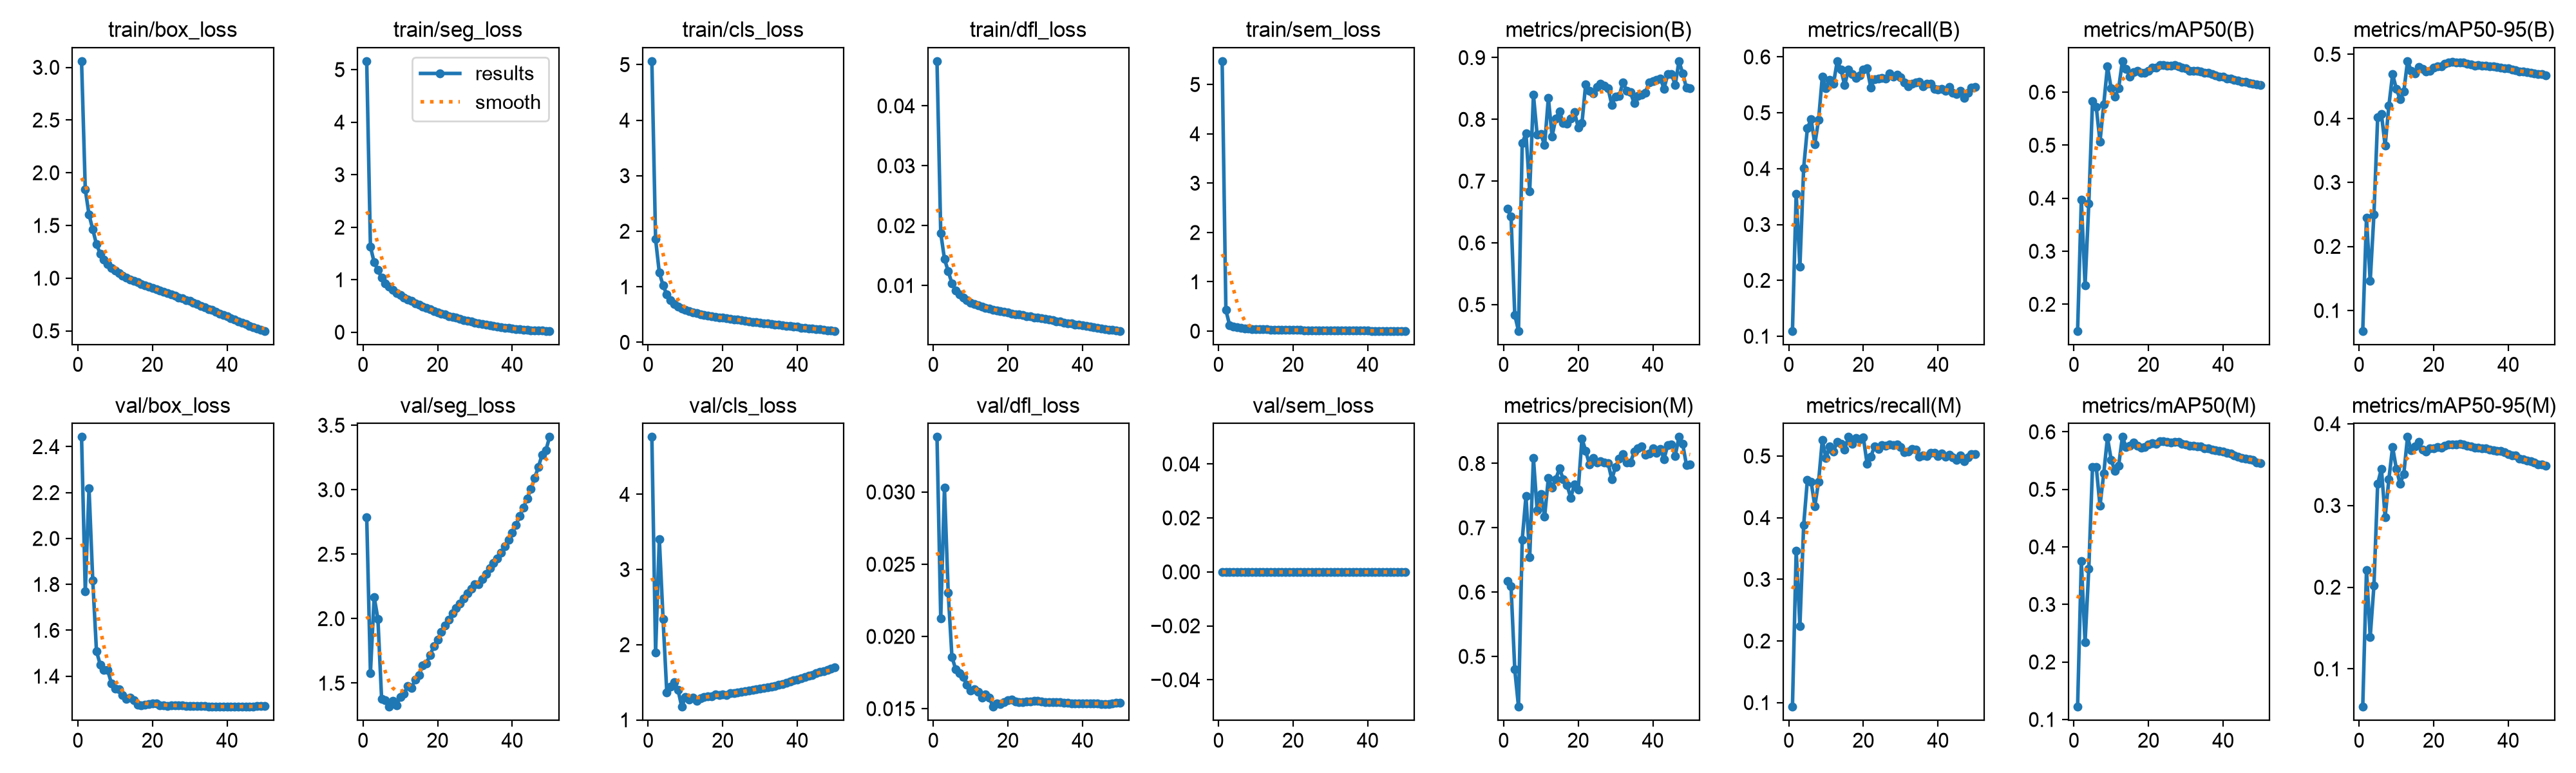

labels.jpg


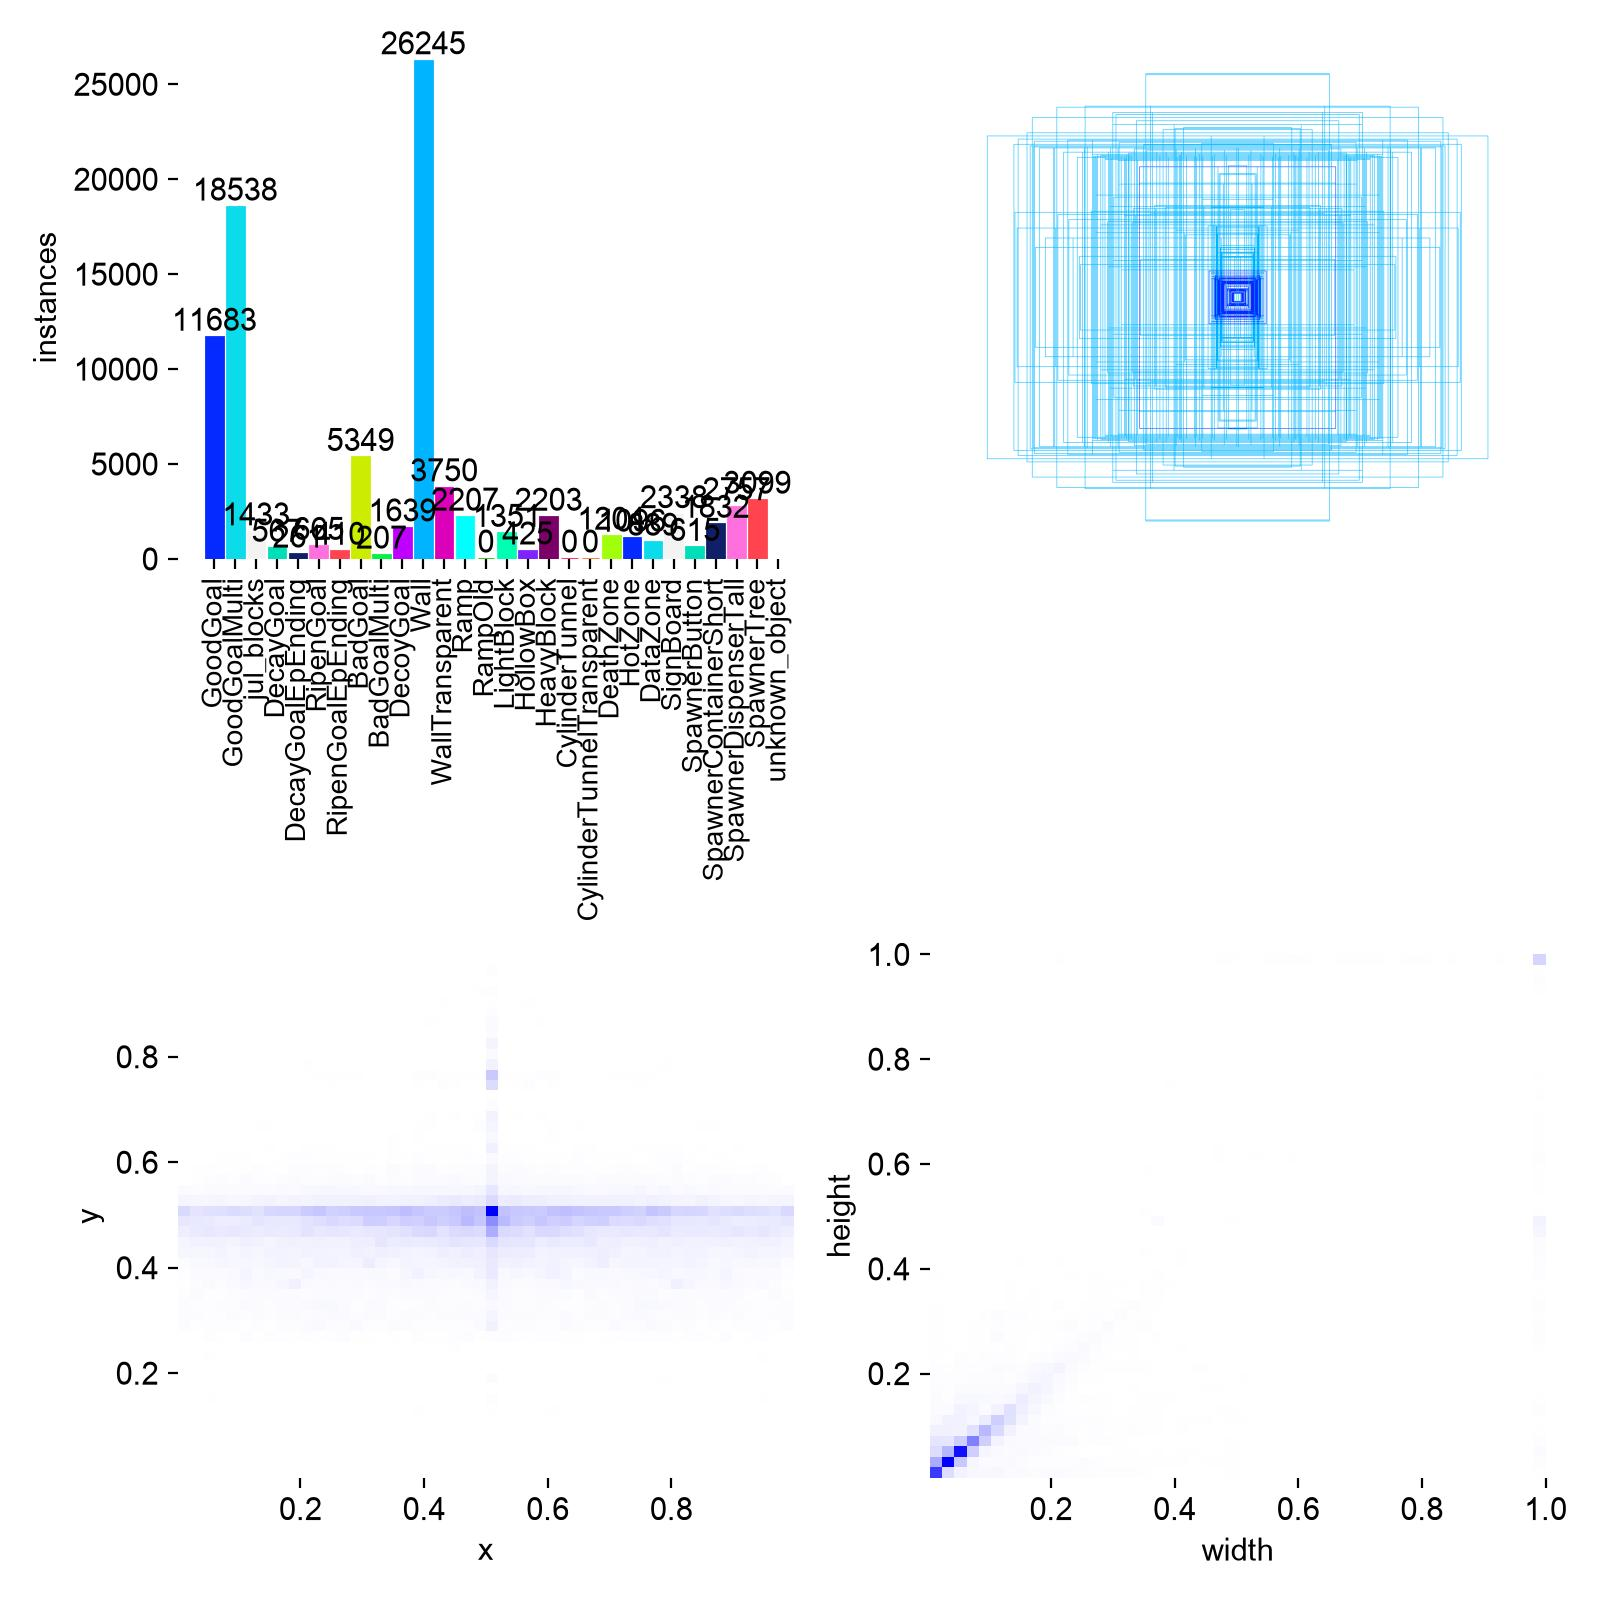

train_batch0.jpg


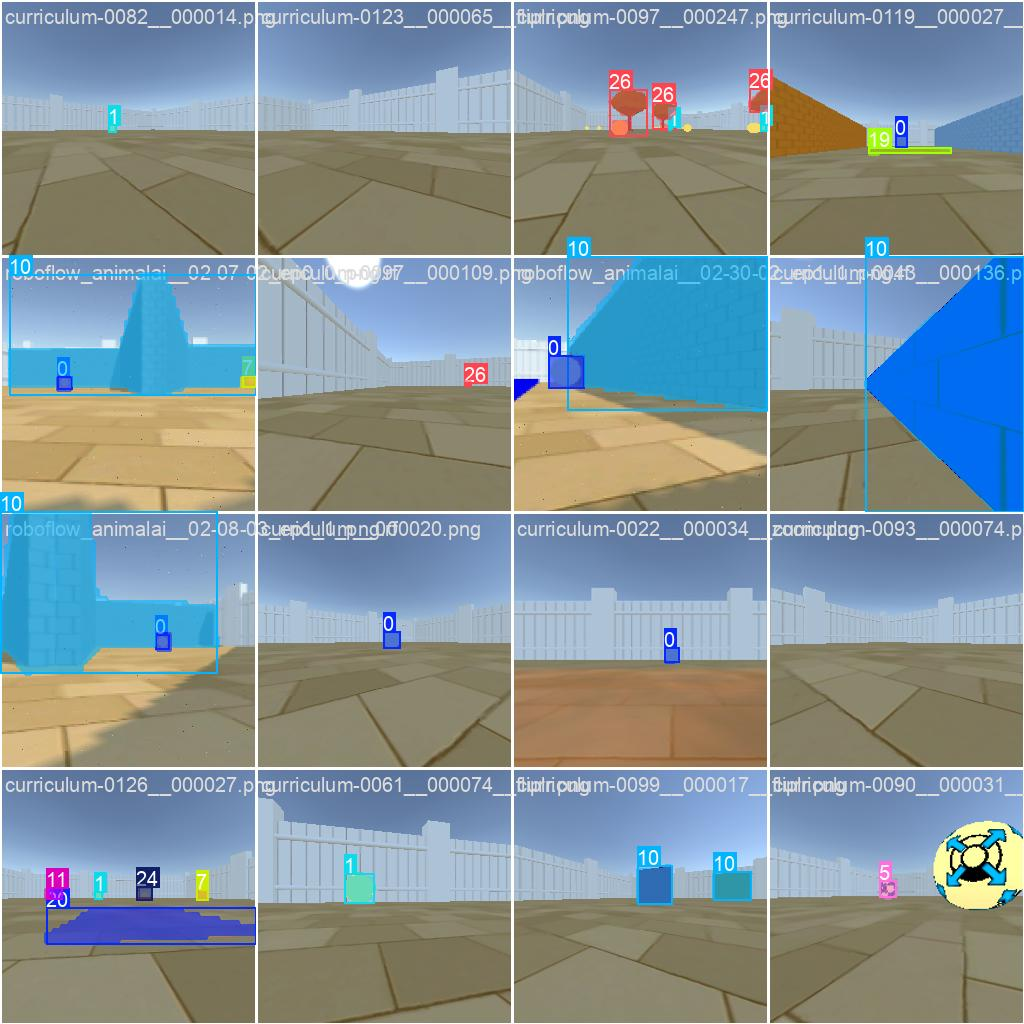

In [9]:
for plot in ("results.png", "labels.jpg", "train_batch0.jpg"):
    path = experiment / plot
    if path.is_file():
        print(plot)
        display(Image(filename=str(path)))

Ultralytics' own box/mask mAP on the test split, plus its plots under `<experiment>/evaluation/`.

In [10]:
inference_model = YOLO(str(checkpoint))
builtin = inference_model.val(
    data=str(data_yaml),
    split="test",
    imgsz=config.image_size,
    batch=config.batch_size,
    workers=config.workers,
    device=config.device,
    project=str(experiment),
    name="evaluation",
    exist_ok=True,
    plots=True,
)
print("box  mAP50 / mAP50-95:", builtin.box.map50, "/", builtin.box.map)
print("mask mAP50 / mAP50-95:", builtin.seg.map50, "/", builtin.seg.map)

Ultralytics 8.4.102 🚀 Python-3.14.4 torch-2.13.0 MPS (Apple M1)
YOLO26n-seg summary (fused): 139 layers, 2,694,344 parameters, 0 gradients, 9.0 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 123.9±102.5 MB/s, size: 21.3 KB)
val: Scanning /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/datasets/animalai_merged/labels/test... 3125 images, 366 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3125/3125 5.4Kit/s 0.6s0.1s
val: New cache created: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/datasets/animalai_merged/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 98/98 2.1it/s 47.7s0.5ss
                   all       3125       9739      0.723      0.609      0.651      0.438      0.644       0.54      0.561      0.302
              GoodGoal       1102       1416      0.817      0.863      0.864      0.518      0.662      0.6

Prediction runs in chunks so a large test split does not hold every result in memory; only the
first `RENDER_LIMIT` overlays are written. `evaluate_predictions` then adds what Ultralytics does
not report: per-class TP/FP/FN, small-object and crowded recall, recall by visibility and occlusion
bucket, calibration. Note these run at `confidence_threshold` from the config (0.001), which sweeps
every detection — read mAP for skill, not the precision column.

In [11]:
CHUNK = 64
RENDER_LIMIT = 50  # rendered overlays are for eyeballing, not a full dump

rendered = experiment / "error_analysis" / "rendered_predictions"
rendered.mkdir(parents=True, exist_ok=True)
predictions = {}
first_result = None
for start in range(0, len(test_records), CHUNK):
    batch = test_records[start : start + CHUNK]
    results = inference_model.predict(
        source=[str(dataset_root / record["image"]) for record in batch],
        imgsz=config.image_size,
        conf=config.confidence_threshold,
        iou=config.nms_iou,
        device=config.device,
        verbose=False,
    )
    for offset, (record, result) in enumerate(zip(batch, results, strict=True)):
        predictions[record["image"]] = result_predictions(result)
        index = start + offset
        if index == 0:
            first_result = result
        if index < RENDER_LIMIT:
            result.save(filename=str(rendered / Path(record["image"]).name))

print(f"predicted {len(predictions)} test frames; "
      f"rendered {min(RENDER_LIMIT, len(test_records))} of them to {rendered}")

sliced_metrics, errors = evaluate_predictions(
    test_records, predictions, class_names, config
)
print(json.dumps(sliced_metrics, indent=2, sort_keys=True, default=str))

predicted 3125 test frames; rendered 50 of them to /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/runs/detector/notebook_yolo26n_seg/error_analysis/rendered_predictions
{
  "calibration": {
    "bins": [
      {
        "accuracy": 0.06394608528215162,
        "count": 32199,
        "lower": 0.0,
        "mean_confidence": 0.01106829710054241,
        "upper": 0.1
      },
      {
        "accuracy": 0.2561340514661879,
        "count": 1671,
        "lower": 0.1,
        "mean_confidence": 0.14411896847094838,
        "upper": 0.2
      },
      {
        "accuracy": 0.3485169491525424,
        "count": 944,
        "lower": 0.2,
        "mean_confidence": 0.2489670197621493,
        "upper": 0.3
      },
      {
        "accuracy": 0.4111888111888112,
        "count": 715,
        "lower": 0.3,
        "mean_confidence": 0.34939990581332386,
        "upper": 0.4
      },
      {
        "accuracy": 0.4585987261146497,
        "count": 628,
        "lower": 0.4

In [12]:
print("false positives:", len(errors["false_positives"]))
print("false negatives:", len(errors["false_negatives"]))
print("transparent-object failures:", len(errors["transparent_object_failures"]))
print("small FN:", len(errors["small_and_distant_object_failures"]["small_false_negatives"]),
      "| distant FN:",
      len(errors["small_and_distant_object_failures"]["distant_false_negatives"]))
print()
print(json.dumps(errors["class_confusion"], indent=2, sort_keys=True))

false positives: 34499
false negatives: 1489
transparent-object failures: 0
small FN: 1217 | distant FN: 322

{
  "labels": [
    "GoodGoal",
    "GoodGoalMulti",
    "jul_blocks",
    "DecayGoal",
    "DecayGoalEpEnding",
    "RipenGoal",
    "RipenGoalEpEnding",
    "BadGoal",
    "BadGoalMulti",
    "DecoyGoal",
    "Wall",
    "WallTransparent",
    "Ramp",
    "RampOld",
    "LightBlock",
    "HollowBox",
    "HeavyBlock",
    "CylinderTunnel",
    "CylinderTunnelTransparent",
    "DeathZone",
    "HotZone",
    "DataZone",
    "SignBoard",
    "SpawnerButton",
    "SpawnerContainerShort",
    "SpawnerDispenserTall",
    "SpawnerTree",
    "unknown_object",
    "__background__",
    "__missed__"
  ],
  "matrix": {
    "BadGoal": {
      "BadGoal": 814,
      "BadGoalMulti": 33,
      "CylinderTunnel": 0,
      "CylinderTunnelTransparent": 0,
      "DataZone": 0,
      "DeathZone": 4,
      "DecayGoal": 0,
      "DecayGoalEpEnding": 1,
      "DecoyGoal": 22,
      "GoodGoal": 197,


In [13]:
from perception.ontology import load_ontology

ontology = load_ontology(ROOT / "configs/ontology.json")
groups = {}
for mapping in ontology.simulator_mappings:
    groups.setdefault(mapping.semantic_class, []).append(mapping.exact_class)
merged_groups = {name: members for name, members in groups.items() if len(members) > 1}

by_exact = sliced_metrics["recall_by_exact_class"]
for semantic_name, members in sorted(merged_groups.items()):
    merged = sliced_metrics["per_class"][semantic_name]
    print(f"{semantic_name}  (merged-class recall={merged['recall']!r}, n={merged['true_positives']+merged['false_negatives']})")
    for member in sorted(members):
        detail = by_exact.get(member, {"objects": 0, "matched": 0, "recall": None})
        flag = "  <-- never found" if detail["objects"] and detail["recall"] == 0.0 else ""
        print(f"    {member:22s} recall={detail['recall']!r:>8}  n={detail['objects']:5d}{flag}")

BadGoal  (merged-class recall=0.862873814733771, n=1371)
    BadGoal                recall=0.860223642172524  n= 1252
    BadGoalBounce          recall=0.8907563025210085  n=  119
DecoyGoal  (merged-class recall=0.8672566371681416, n=113)
    DecoyGoal              recall=0.896551724137931  n=   29
    DecoyGoalBounce        recall=0.7073170731707317  n=   41
    DecoyGoalMulti         recall=     1.0  n=   43
GoodGoal  (merged-class recall=0.8990112994350282, n=1416)
    GoodGoal               recall=0.8987455197132617  n= 1116
    GoodGoalBounce         recall=     0.9  n=  300
GoodGoalMulti  (merged-class recall=0.8575072886297376, n=2744)
    GoodGoalMulti          recall=0.8857908847184987  n= 1865
    GoodGoalMultiBounce    recall=  0.9375  n=  224
    GrowGoal               recall=0.7428571428571429  n=   35
    ShrinkGoal             recall=     0.0  n=    2  <-- never found
jul_blocks  (merged-class recall=0.9626168224299065, n=321)
    JBlock                 recall=0.96478873

The merged dataset mixes capture polygons with rectangles widened from box-only labels, so score
the sources separately. Mask quality is only meaningful on the `capture` slice.

In [14]:
by_source = {}
for record in test_records:
    by_source.setdefault(record.get("source", "capture"), []).append(record)

for source, subset in sorted(by_source.items()):
    metrics, _ = evaluate_predictions(subset, predictions, class_names, config)
    per_class = {
        name: value["recall"]
        for name, value in metrics["per_class"].items()
        if value["true_positives"] or value["false_negatives"]
    }
    print(f"{source:20s} frames={len(subset):5d} "
          f"mask_source={subset[0].get('mask_source')}")
    print(f"  recall by class: {per_class}")
    print(f"  small-object recall: {metrics['small_object_recall']}")

capture              frames= 1496 mask_source=polygon
  recall by class: {'GoodGoal': 0.9118942731277533, 'GoodGoalMulti': 0.8322542672160094, 'jul_blocks': 0.9626168224299065, 'DecayGoal': 0.9629629629629629, 'RipenGoal': 0.675, 'RipenGoalEpEnding': 0.9722222222222222, 'BadGoal': 0.8680555555555556, 'BadGoalMulti': 0.9705882352941176, 'DecoyGoal': 0.8672566371681416, 'Wall': 0.844551282051282, 'WallTransparent': 0.8461538461538461, 'Ramp': 0.5234375, 'LightBlock': 0.9672131147540983, 'HollowBox': 0.7752808988764045, 'HeavyBlock': 0.875, 'DeathZone': 0.8256578947368421, 'HotZone': 0.3488372093023256, 'DataZone': 0.8837209302325582, 'SignBoard': 0.6428571428571429, 'SpawnerContainerShort': 0.868, 'SpawnerDispenserTall': 0.502906976744186, 'SpawnerTree': 0.9437340153452686}
  small-object recall: {'objects': 3709, 'matched': 2896, 'recall': 0.7808034510649771}
roboflow_animalai    frames= 1629 mask_source=mixed
  recall by class: {'GoodGoal': 0.8929313929313929, 'GoodGoalMulti': 0.898564

Writes the run record: metrics, error analysis, the stripped `inference.pt`, one validated
non-privileged `DetectionFrame`, and reproducibility manifests.

In [15]:
write_json(
    experiment / "metrics.json",
    {
        "ultralytics": ultralytics_metrics(builtin),
        "object_level_at_confidence_threshold": sliced_metrics,
    },
)
error_root = experiment / "error_analysis"
for name, payload in errors.items():
    write_json(error_root / f"{name}.json", payload)

artifact_root = experiment / "artifacts"
artifact_root.mkdir(parents=True, exist_ok=True)
shutil.copy2(checkpoint, artifact_root / "inference.pt")

first_record = test_records[0]
first_detection = detection_from_result(
    first_result,
    FrameStamp(
        episode_id=first_record["episode_id"],
        frame_index=first_record["frame_index"],
        timestamp_seconds=first_record["timestamp_seconds"],
    ),
    SourceMetadata(SourceType.DETECTOR, "ultralytics_yolo_segmentation", ultralytics.__version__,
                   configuration_id=config.experiment_name),
)
first_frame = first_detection.frame
inference_root = experiment / "inference"
inference_root.mkdir(parents=True, exist_ok=True)
(inference_root / "detection_frame.json").write_text(first_frame.to_json(), encoding="utf-8")
if first_detection.masks is not None:  # instance map the frame's MaskReferences point at
    from perception.inference.detector import mask_path
    from PIL import Image as PILImage
    mask_file = inference_root / mask_path(first_frame.stamp)
    mask_file.parent.mkdir(parents=True, exist_ok=True)
    PILImage.fromarray(first_detection.masks).save(mask_file)
DetectionFrame.from_json_file(inference_root / "detection_frame.json")

write_json(
    experiment / "environment.json",
    {
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "ultralytics": ultralytics.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_device_count": torch.cuda.device_count(),
        "mps_built": bool(mps and mps.is_built()),
        "mps_available": bool(mps and mps.is_available()),
        "packages": {
            distribution.metadata["Name"]: distribution.version
            for distribution in importlib.metadata.distributions()
            if distribution.metadata["Name"]
        },
    },
)
write_json(
    experiment / "manifest.json",
    {
        "config": {field: getattr(config, field) for field in config.__dataclass_fields__},
        "data_yaml": str(data_yaml),
        "checkpoint": str(artifact_root / "inference.pt"),
        "test_frames": len(test_records),
        "seed": config.seed,
        "command": "notebooks/04_train_yolo26_detector.ipynb",
    },
)
print("wrote artifacts under", experiment)
for path in sorted(experiment.rglob("*.json")):
    print(" ", path.relative_to(experiment))

wrote artifacts under /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/runs/detector/notebook_yolo26n_seg
  environment.json
  error_analysis/calibration.json
  error_analysis/class_confusion.json
  error_analysis/false_negatives.json
  error_analysis/false_positives.json
  error_analysis/small_and_distant_object_failures.json
  error_analysis/transparent_object_failures.json
  inference/detection_frame.json
  manifest.json
  metrics.json


Rendered predictions from the test split.

curriculum-0003__000000.png


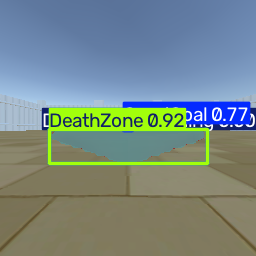

curriculum-0003__000001.png


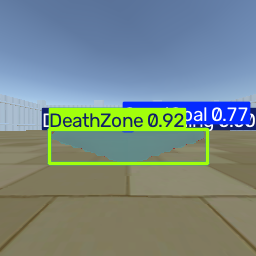

curriculum-0003__000002.png


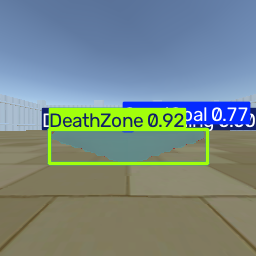

curriculum-0003__000003.png


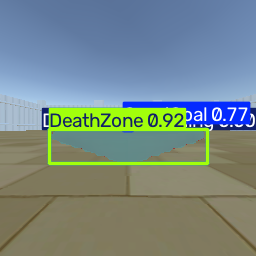

curriculum-0003__000004.png


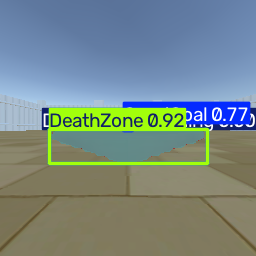

curriculum-0003__000005.png


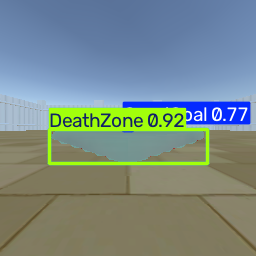

curriculum-0003__000006.png


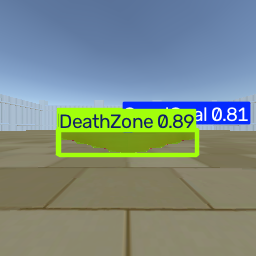

curriculum-0003__000007.png


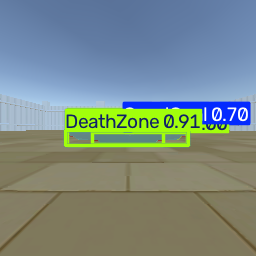

curriculum-0003__000008.png


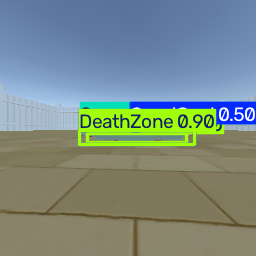

curriculum-0003__000009.png


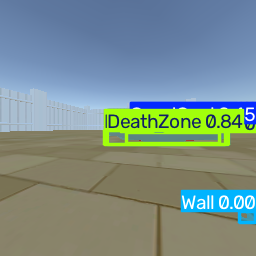

curriculum-0003__000010.png


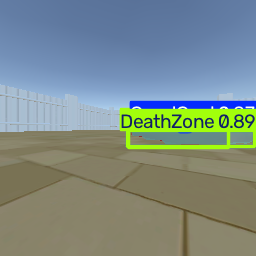

curriculum-0003__000011.png


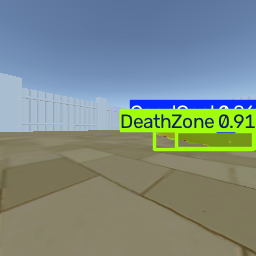

In [16]:
for path in sorted(rendered.glob("*"))[:12]:
    print(path.name)
    display(Image(filename=str(path)))